# Контрольная точка 4
# Задание 2
## Линейный дискриминантный анализ

Данные и протокол те же, что в КТ3 и задании 1: US Accidents (March 2023), дедупликация по `group_id` (одна авария = одна строка), подвыборка по хешу ID, признаки беру из `task1_selected_features.json`.

Важный момент: число дискриминантных компонент LDA ограничено `min(n_features, n_classes - 1)`. Цель `Severity >= 3` бинарная, для неё компонента ровно одна, подбирать нечего. Поэтому смотрю два случая:

1. Бинарная цель: единственная ось Фишера, сверяю sklearn с ручным расчётом через матрицы разброса.
2. Исходная `Severity` (4 класса): перебор `n_components` от 1 до 3, качество самого LDA и связки LDA + логистическая регрессия.


In [1]:
import os
import time
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (roc_auc_score, f1_score,
                             balanced_accuracy_score, accuracy_score)

SEED = 42
rng = np.random.RandomState(SEED)
plt.rcParams["figure.dpi"] = 110

# наборы признаков из задания 1
with open("../task_1/task1_selected_features.json", encoding="utf-8") as f:
    sets1 = json.load(f)
selected = sets1["selected"]
kt3_cols = sets1["kt3_baseline"]

# пути к данным - как в задании 1
RAW_CANDIDATES = [
    r"C:\Users\musai\.cache\kagglehub\datasets\sobhanmoosavi\us-accidents\versions\13\US_Accidents_March23.csv",
    "US_Accidents_March23.csv",
    "data/US_Accidents_March23.csv",
]
GROUPED_CANDIDATES = ["df_with_groups.csv.gz", "../kt3/df_with_groups.csv.gz",
                      "KTs/kt3/df_with_groups.csv.gz", "../../kt3/df_with_groups.csv.gz",]

KEEP_PERMILLE = 60      # та же подвыборка, что в задании 1
MAX_ROWS = 450_000
CHUNKSIZE = 400_000

# month/hour/na_* считаются на месте, из CSV их читать не нужно
DERIVED = {"month", "hour", "na_Precipitation(in)"}
USECOLS = ((set(kt3_cols) | set(selected)) - DERIVED) | {"Start_Time", "Severity"}
print("отобрано в задании 1:", selected)
print("колонок читаю из CSV:", len(USECOLS) + 1)  # + ID

отобрано в задании 1: ['Street', 'Source', 'Airport_Code', 'na_Precipitation(in)', 'Zipcode', 'State', 'Traffic_Signal', 'month', 'hour', 'City']
колонок читаю из CSV: 24


In [2]:
def pick_path(cands):
    for p in cands:
        if os.path.exists(p):
            return p
    return None

raw_path = pick_path(RAW_CANDIDATES)
if raw_path is None:
    import kagglehub
    raw_path = os.path.join(kagglehub.dataset_download("sobhanmoosavi/us-accidents"),
                            "US_Accidents_March23.csv")
groups_path = pick_path(GROUPED_CANDIDATES)
if groups_path is None:
    raise FileNotFoundError("не найден df_with_groups.csv.gz из КТ3")
print("источник:", raw_path)

# проход 1: отбор по хешу ID, файл отсортирован по источнику и времени, читаю целиком
t0 = time.time()
parts = []
for chunk in pd.read_csv(raw_path, usecols=lambda c: c in USECOLS or c == "ID",
                         chunksize=CHUNKSIZE, low_memory=False):
    h = pd.util.hash_array(chunk["ID"].to_numpy()) % 1000
    parts.append(chunk.loc[h < KEEP_PERMILLE])
raw = pd.concat(parts, ignore_index=True)
del parts
print(f"отобрано {len(raw):,} строк ({time.time() - t0:.1f}s)")

# проход 2: group_id из файла КТ3, только для отобранных ID
need = set(raw["ID"])
gparts = []
for chunk in pd.read_csv(groups_path, usecols=["ID", "group_id"], chunksize=CHUNKSIZE):
    gparts.append(chunk[chunk["ID"].isin(need)])
gid = pd.concat(gparts, ignore_index=True).drop_duplicates("ID").set_index("ID")["group_id"]
raw["group_id"] = raw["ID"].map(gid)
raw = raw[raw["group_id"].notna()].drop(columns="ID").reset_index(drop=True)
raw["group_id"] = raw["group_id"].astype("int64")
del gparts, gid, need

# усечение по группам и дедупликация - порядок тот же, что в задании 1
if len(raw) > MAX_ROWS:
    gs = raw["group_id"].value_counts()
    order = rng.permutation(gs.index.to_numpy())
    n_g = int((gs.loc[order].cumsum() <= MAX_ROWS).sum())
    raw = raw[raw["group_id"].isin(set(order[:n_g]))].reset_index(drop=True)

agg = {c: "first" for c in raw.columns if c not in ("group_id", "Severity")}
agg["Severity"] = "median"
df = raw.sort_values("group_id").groupby("group_id", as_index=False).agg(agg)
del raw

df["y"] = (df["Severity"] >= 3).astype(int)
# медиана внутри группы могла получиться дробной, для 4-классовой части округляю
df["sev4"] = df["Severity"].round().clip(1, 4).astype(int)
print(f"дедупликация: {len(df):,} аварий, доля тяжёлых {df['y'].mean():.4f}")
print("распределение Severity:", df["sev4"].value_counts().sort_index().to_dict())

источник: C:\Users\musai\.cache\kagglehub\datasets\sobhanmoosavi\us-accidents\versions\13\US_Accidents_March23.csv
отобрано 463,800 строк (32.2s)
дедупликация: 443,663 аварий, доля тяжёлых 0.1967
распределение Severity: {1: 3835, 2: 352560, 3: 75676, 4: 11592}


In [3]:
# производные признаки и кодирование - как в задании 1
start = pd.to_datetime(df["Start_Time"], errors="coerce", format="%Y-%m-%d %H:%M:%S")
df["hour"] = start.dt.hour
df["month"] = start.dt.month
df["na_Precipitation(in)"] = df["Precipitation(in)"].isna().astype(float)

KT3_NUM = ["Distance(mi)", "Temperature(F)", "Humidity(%)", "Pressure(in)",
           "Visibility(mi)", "Wind_Speed(mph)", "Precipitation(in)"]
KT3_BIN = ["Bump", "Crossing", "Junction", "Railway", "Station", "Stop",
           "Traffic_Signal", "Amenity"]
num_features = KT3_NUM + ["month", "hour"]
bin_features = KT3_BIN + ["na_Precipitation(in)"]
cat_features = [c for c in selected if c not in num_features + bin_features]

def to_binary(s):
    if s.dtype == bool:
        return s.astype(float)
    mp = {True: 1.0, False: 0.0, "True": 1.0, "False": 0.0, 1: 1.0, 0: 0.0}
    return s.astype("object").map(mp).astype(float)

def fit_te(s, y, m=30):
    prior = float(np.mean(y))
    key = s.astype("object").where(s.notna(), "__na__")
    g = pd.DataFrame({"k": key.to_numpy(), "y": np.asarray(y)}).groupby("k")["y"].agg(["sum", "count"])
    return ((g["sum"] + m * prior) / (g["count"] + m)).to_dict(), prior

def apply_te(s, mapping, prior):
    key = s.astype("object").where(s.notna(), "__na__")
    return key.map(mapping).fillna(prior).astype(float).to_numpy()

def build_features(dtr, dte, ytr, n_splits=5, m=30):
    Xtr = pd.DataFrame(index=dtr.index)
    Xte = pd.DataFrame(index=dte.index)
    for c in num_features:
        v = pd.to_numeric(dtr[c], errors="coerce")
        med = float(v.median()) if v.notna().any() else 0.0
        Xtr[c] = v.fillna(med).astype("float32")
        Xte[c] = pd.to_numeric(dte[c], errors="coerce").fillna(med).astype("float32")
    for c in bin_features:
        Xtr[c] = to_binary(dtr[c]).fillna(0.0).astype("float32")
        Xte[c] = to_binary(dte[c]).fillna(0.0).astype("float32")
    # категории - сглаженный target encoding, на train строго out-of-fold
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    for c in cat_features:
        oof = np.zeros(len(dtr))
        for tr, va in skf.split(np.zeros(len(dtr)), ytr):
            mp, pr = fit_te(dtr[c].iloc[tr], ytr.iloc[tr], m=m)
            oof[va] = apply_te(dtr[c].iloc[va], mp, pr)
        mp, pr = fit_te(dtr[c], ytr, m=m)
        Xtr[c] = oof.astype("float32")
        Xte[c] = apply_te(dte[c], mp, pr).astype("float32")
    return Xtr, Xte

dtr, dte = train_test_split(df, test_size=0.25, stratify=df["y"], random_state=SEED)
dtr = dtr.reset_index(drop=True)
dte = dte.reset_index(drop=True)
ytr, yte = dtr["y"], dte["y"]

t0 = time.time()
Xtr, Xte = build_features(dtr, dte, ytr)
# для svd-солвера масштабирование ничего не меняет, а для eigen со сжатием ковариации важно
scaler = StandardScaler().fit(Xtr)
Xtr_s = pd.DataFrame(scaler.transform(Xtr), columns=Xtr.columns)
Xte_s = pd.DataFrame(scaler.transform(Xte), columns=Xte.columns)
print(f"матрица: train {Xtr_s.shape}, test {Xte_s.shape} ({time.time() - t0:.1f}s)")

матрица: train (332747, 24), test (110916, 24) (3.7s)


## Часть 1. Бинарная цель: одна компонента

LDA ищет направления, где отношение межклассового разброса к внутриклассовому максимально. Ранг межклассовой матрицы `Sb` равен `C - 1`, для двух классов это 1, то есть существует единственное направление `w = Sw^-1 (mu1 - mu0)`. Посчитаю его руками и сравню со `scalings_` у sklearn.

Базовый набор КТ3 оставляю для сопоставимости (в нём есть `Distance(mi)`, помеченный в задании 1 как утечка, - на это надо смотреть при чтении таблицы).

,n_features,roc_auc,f1,bal_acc
set,,,,
KT3 baseline,15,0.6288,0.0003,0.5000
KT4 selected,10,0.8551,0.6362,0.7545


|cos| ручного направления и scalings_ у sklearn: 1.000000
ROC-AUC ручной проекции: 0.8551
LogReg поверх одной оси - монотонное преобразование, ROC-AUC не изменится


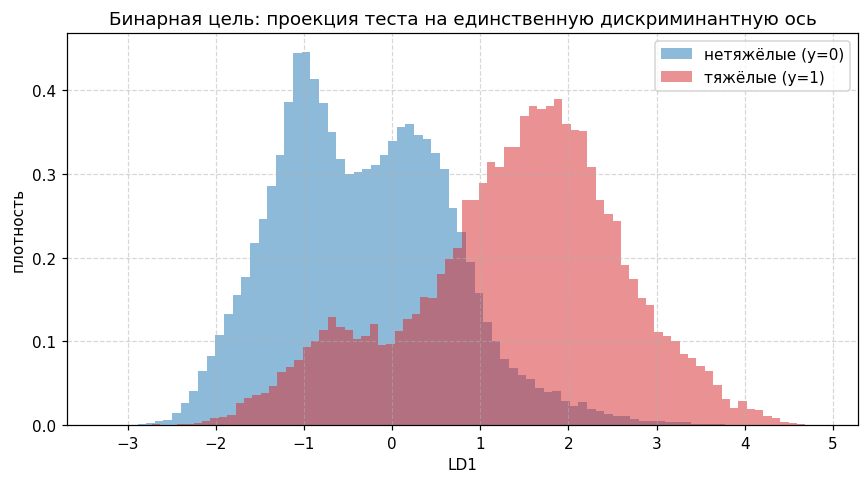

In [8]:
# бинарная цель: у LDA здесь ровно одна компонента, перебирать нечего
rows = []
projs = {}
for name, cols in [("KT3 baseline", kt3_cols), ("KT4 selected", selected)]:
    lda = LinearDiscriminantAnalysis(solver="svd").fit(Xtr_s[cols], ytr)
    p = lda.predict_proba(Xte_s[cols])[:, 1]
    pred = (p >= 0.5).astype(int)
    rows.append({"set": name, "n_features": len(cols),
                 "roc_auc": roc_auc_score(yte, p),
                 "f1": f1_score(yte, pred, zero_division=0),
                 "bal_acc": balanced_accuracy_score(yte, pred)})
    projs[name] = lda.transform(Xte_s[cols])[:, 0]
bin_df = pd.DataFrame(rows).set_index("set")
display(bin_df.round(4))

# руками: направление Фишера w = Sw^-1 (mu1 - mu0) на отобранном наборе
Xs = Xtr_s[selected].to_numpy()
yv = ytr.to_numpy()
mu0 = Xs[yv == 0].mean(axis=0)
mu1 = Xs[yv == 1].mean(axis=0)
Xc = Xs - np.where(yv[:, None] == 1, mu1, mu0)
Sw = Xc.T @ Xc / len(Xc)
w = np.linalg.solve(Sw + 1e-8 * np.eye(len(selected)), mu1 - mu0)
w /= np.linalg.norm(w)

lda_sel = LinearDiscriminantAnalysis(solver="svd").fit(Xtr_s[selected], ytr)
w_sk = lda_sel.scalings_[:, 0]
w_sk /= np.linalg.norm(w_sk)
cos_w = abs(float(w @ w_sk))
auc_manual = roc_auc_score(yte, Xte_s[selected].to_numpy() @ w)
print(f"|cos| ручного направления и scalings_ у sklearn: {cos_w:.6f}")
print(f"ROC-AUC ручной проекции: {auc_manual:.4f}")
print("LogReg поверх одной оси - монотонное преобразование, ROC-AUC не изменится")

fig, ax = plt.subplots(figsize=(8, 4.5))
z = projs["KT4 selected"]
for cls, lab, c in [(0, "нетяжёлые (y=0)", "tab:blue"), (1, "тяжёлые (y=1)", "tab:red")]:
    ax.hist(z[yte.to_numpy() == cls], bins=80, density=True, alpha=0.5, label=lab, color=c)
ax.set_xlabel("LD1")
ax.set_ylabel("плотность")
ax.set_title("Бинарная цель: проекция теста на единственную дискриминантную ось")
ax.legend()
ax.grid(ls="--", alpha=0.5)
plt.tight_layout()
plt.savefig("task2_lda_binary_projection.png", dpi=150, bbox_inches="tight")
plt.show()

## Часть 2. Severity как 4 класса: подбор числа компонент

Чтобы вопрос об оптимальном `n_components` имел смысл, беру исходную четырёхклассовую `Severity`. Максимум компонент - `min(10, 4 - 1) = 3`.

Для каждого k сравниваю два классификатора: сам LDA и LogReg поверх k дискриминант. Метрики - macro F1, balanced accuracy и ROC-AUC (ovr, macro). Решатель eigen со сжатием ковариации по Ledoit-Wolf: признаки после target encoding скоррелированы, выборочная ковариация может быть плохо обусловлена. Пунктир на графике - LogReg на всех 10 признаках без сжатия, как ориентир.

классы: {1: 2897, 2: 264399, 3: 56790, 4: 8661} | max_k = 3


,k,clf,accuracy,f1_macro,bal_acc,roc_auc_ovr
0,1,LDA,0.8709,0.4044,0.3996,0.8354
1,1,LDA + LogReg,0.8706,0.4023,0.3955,0.7177
2,2,LDA,0.8709,0.4044,0.3996,0.8354
3,2,LDA + LogReg,0.8722,0.4037,0.3965,0.8229
4,3,LDA,0.8709,0.4044,0.3996,0.8354
5,3,LDA + LogReg,0.8722,0.4037,0.3965,0.8355


explained_variance_ratio_ по осям: [0.9411 0.0524 0.0091]
LogReg на всех признаках: {'accuracy': 0.873, 'f1_macro': 0.4045, 'bal_acc': 0.397, 'roc_auc_ovr': 0.8419}


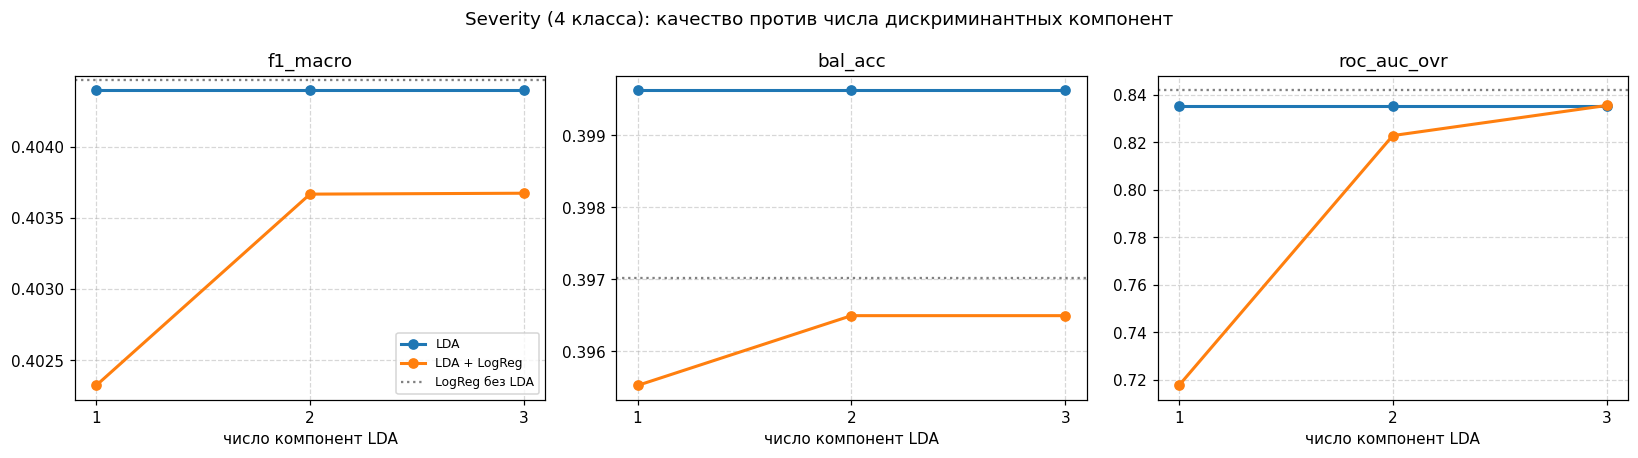

In [5]:
ytr4, yte4 = dtr["sev4"], dte["sev4"]
max_k = min(len(selected), ytr4.nunique() - 1)
print("классы:", ytr4.value_counts().sort_index().to_dict(), "| max_k =", max_k)

def mc_metrics(y_true, proba, classes):
    pred = classes[proba.argmax(axis=1)]
    try:
        roc = roc_auc_score(y_true, proba, multi_class="ovr", average="macro")
    except ValueError:
        roc = np.nan  # если какого-то класса не оказалось в тесте
    return {"accuracy": accuracy_score(y_true, pred),
            "f1_macro": f1_score(y_true, pred, average="macro"),
            "bal_acc": balanced_accuracy_score(y_true, pred),
            "roc_auc_ovr": roc}

rows, evr = [], {}
for k in range(1, max_k + 1):
    lda = LinearDiscriminantAnalysis(n_components=k, solver="eigen", shrinkage="auto")
    lda.fit(Xtr_s[selected], ytr4)
    Ztr, Zte = lda.transform(Xtr_s[selected]), lda.transform(Xte_s[selected])
    lr = LogisticRegression(max_iter=1000).fit(Ztr, ytr4)
    evr[k] = lda.explained_variance_ratio_
    for cname, model, Xin in [("LDA", lda, Xte_s[selected]), ("LDA + LogReg", lr, Zte)]:
        rows.append({"k": k, "clf": cname,
                     **mc_metrics(yte4, model.predict_proba(Xin), model.classes_)})

res4 = pd.DataFrame(rows)
res4.to_csv("task2_lda_components.csv", index=False, encoding="utf-8-sig")
display(res4.round(4))
print("explained_variance_ratio_ по осям:", np.round(evr[max_k], 4))

# ориентир: LogReg на всех признаках, без сжатия
lr_full = LogisticRegression(max_iter=1000).fit(Xtr_s[selected], ytr4)
full = mc_metrics(yte4, lr_full.predict_proba(Xte_s[selected]), lr_full.classes_)
print("LogReg на всех признаках:", {m: round(v, 4) for m, v in full.items()})

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, met in zip(axes, ["f1_macro", "bal_acc", "roc_auc_ovr"]):
    for cname, g in res4.groupby("clf"):
        ax.plot(g["k"], g[met], marker="o", lw=2, label=cname)
    ax.axhline(full[met], ls=":", c="gray", lw=1.5, label="LogReg без LDA")
    ax.set_xticks(range(1, max_k + 1))
    ax.set_xlabel("число компонент LDA")
    ax.set_title(met)
    ax.grid(ls="--", alpha=0.5)
axes[0].legend(fontsize=8)
fig.suptitle("Severity (4 класса): качество против числа дискриминантных компонент")
plt.tight_layout()
plt.savefig("task2_lda_components.png", dpi=150, bbox_inches="tight")
plt.show()

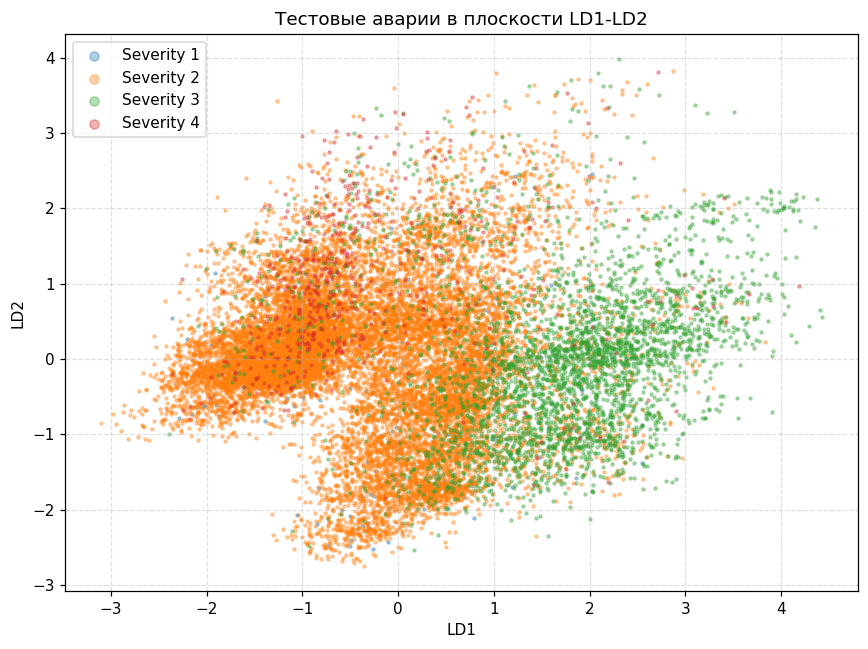

центроиды классов в плоскости LD1-LD2:


,LD1,LD2
sev,,
1,-0.283,-0.788
2,-0.333,-0.026
3,1.691,0.027
4,-0.370,0.986


In [6]:
# как классы выглядят в плоскости первых двух осей
lda2 = LinearDiscriminantAnalysis(n_components=2, solver="eigen", shrinkage="auto")
lda2.fit(Xtr_s[selected], ytr4)
Z = lda2.transform(Xte_s[selected])
idx = rng.choice(len(Z), size=min(20_000, len(Z)), replace=False)

fig, ax = plt.subplots(figsize=(8, 6))
for cls in sorted(yte4.unique()):
    m = (yte4.to_numpy() == cls)[idx]
    ax.scatter(Z[idx][m, 0], Z[idx][m, 1], s=4, alpha=0.35, label=f"Severity {cls}")
ax.set_xlabel("LD1")
ax.set_ylabel("LD2")
ax.set_title("Тестовые аварии в плоскости LD1-LD2")
ax.legend(markerscale=3)
ax.grid(ls="--", alpha=0.4)
plt.tight_layout()
plt.savefig("task2_lda_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

cent = pd.DataFrame(Z, columns=["LD1", "LD2"]).assign(sev=yte4.to_numpy()).groupby("sev").mean()
print("центроиды классов в плоскости LD1-LD2:")
display(cent.round(3))

In [7]:
# минимальное k, неотличимое от лучшего по macro F1 (разница < 0.002 - шум)
def best_k(sub, tol=0.002):
    mx = sub["f1_macro"].max()
    return int(sub.loc[sub["f1_macro"] >= mx - tol, "k"].min())

lines = [
    "Задание 2. Линейный дискриминантный анализ (US Accidents).",
    f"Выборка: {len(df):,} аварий после дедупликации, признаков из задания 1: {len(selected)}.",
    "",
    "1. Бинарная цель Severity >= 3: число компонент ограничено min(n_features, C-1) = 1, подбор вырожден.",
]
for name, r in bin_df.iterrows():
    lines.append(f"   {name:14s} ROC-AUC {r['roc_auc']:.4f}, F1 {r['f1']:.4f}, bal.acc {r['bal_acc']:.4f}")
lines += [
    f"   Ручное направление Фишера против sklearn: |cos| = {cos_w:.6f}, ROC-AUC проекции {auc_manual:.4f}.",
    "",
    f"2. Severity как {ytr4.nunique()} класса, перебор k = 1..{max_k}:",
]
for _, r in res4.iterrows():
    lines.append(f"   k={int(r['k'])} {r['clf']:13s} F1macro {r['f1_macro']:.4f}, "
                 f"bal.acc {r['bal_acc']:.4f}, ROC-AUC(ovr) {r['roc_auc_ovr']:.4f}")
lines += [f"   explained_variance_ratio_ по осям: {np.round(evr[max_k], 4)}", ""]
lines += ["3. Оптимальное число компонент (минимальное k в пределах 0.002 от максимума macro F1):"]
for cname, g in res4.groupby("clf"):
    k_opt = best_k(g)
    v = g.loc[g["k"] == k_opt, "f1_macro"].iloc[0]
    lines.append(f"   {cname}: k = {k_opt} (F1macro {v:.4f})")
lines += [
    f"   Ориентир без сжатия, LogReg на всех {len(selected)} признаках: F1macro {full['f1_macro']:.4f}.",
    "",
    "Артефакты: task2_lda_components.csv, task2_summary.txt, графики task2_*.png.",
]
summary = "\n".join(lines)
print(summary)
with open("task2_summary.txt", "w", encoding="utf-8") as f:
    f.write(summary)

Задание 2. Линейный дискриминантный анализ (US Accidents).
Выборка: 443,663 аварий после дедупликации, признаков из задания 1: 10.

1. Бинарная цель Severity >= 3: число компонент ограничено min(n_features, C-1) = 1, подбор вырожден.
   KT3 baseline   ROC-AUC 0.6288, F1 0.0003, bal.acc 0.5000
   KT4 selected   ROC-AUC 0.8551, F1 0.6362, bal.acc 0.7545
   Ручное направление Фишера против sklearn: |cos| = 1.000000, ROC-AUC проекции 0.8551.

2. Severity как 4 класса, перебор k = 1..3:
   k=1 LDA           F1macro 0.4044, bal.acc 0.3996, ROC-AUC(ovr) 0.8354
   k=1 LDA + LogReg  F1macro 0.4023, bal.acc 0.3955, ROC-AUC(ovr) 0.7177
   k=2 LDA           F1macro 0.4044, bal.acc 0.3996, ROC-AUC(ovr) 0.8354
   k=2 LDA + LogReg  F1macro 0.4037, bal.acc 0.3965, ROC-AUC(ovr) 0.8229
   k=3 LDA           F1macro 0.4044, bal.acc 0.3996, ROC-AUC(ovr) 0.8354
   k=3 LDA + LogReg  F1macro 0.4037, bal.acc 0.3965, ROC-AUC(ovr) 0.8355
   explained_variance_ratio_ по осям: [0.9411 0.0524 0.0091]

3. Оптимально

### Вывод

1. **Бинарная цель: k = 1 без выбора.** Число компонент LDA ограничено min(n_features, C - 1), для двух классов это 1, подбор вырожден. Ручное направление Фишера совпадает с sklearn, а логистическая регрессия поверх одной оси не меняет ROC-AUC - это монотонное преобразование той же проекции.
2. **Для 4-классовой Severity оптимально k = 1.** Метрики LDA при k = 1..3 совпадают до 4 знаков (accuracy 0.8709, macro F1 0.4044, bal.acc 0.3996, ROC-AUC ovr 0.8354). Первая ось забирает 94.1% объяснённого разброса, остальные - 5.2% и 0.9%.
3. **Связке LDA + LogReg для ранжирования нужны 2-3 оси.** Macro F1 почти не меняется (0.4023 -> 0.4037), но ROC-AUC ovr растёт с 0.7177 (k = 1) до 0.8229 (k = 2) и 0.8355 (k = 3): на одной координате мультиномиальный LogReg не ранжирует 4 класса. Для жёсткой классификации достаточно одной компоненты.
4. **Сжатие бесплатно.** LogReg на всех 10 признаках: F1macro 0.4045, LDA на одной оси: 0.4044. Вся линейно извлекаемая информация укладывается в одну дискриминанту.
5. **Геометрия не порядковая.** LD1 отделяет класс 3 от остальных (центроид 1.69 против ~ -0.3), LD2 разводит редкие классы 1 и 4 по разные стороны (-0.79 и +0.99). Severity - не порядковая шкала в пространстве признаков; бинарная цель работает потому, что 87% положительного класса - это класс 3.
6. **Дисбаланс.** Класс 2 - 79.5% выборки, редкие 1 и 4 почти не распознаются: macro F1 ~ 0.40 при accuracy 0.8709 (тривиальный "всегда класс 2" даёт 0.7947). Нужны class_weight или подбор порогов, как в КТ3.

Ограничения: одно разбиение train/test; target encoding закодирован под бинарную цель; 4-классовый ROC-AUC несопоставим напрямую с бинарным из задания 1.